# Indian Road Accidents — Statistical Analysis

**Purpose:** Explore distributions, patterns, relationships, and statistically significant associations in the supplied road-accident dataset, addressing all five stated problem statements.

**Project questions**
1. Distribution of accident severity (minor, major, fatal).
2. Association between weather and severity.
3. Patterns by hour, weekday, and weekend.
4. Accident counts/causes by road type and traffic density.
5. Casualties in relation to severity and vehicles involved.

> **Interpretation boundary:** This is an accident-record dataset, not a traffic-exposure dataset. Counts and associations describe the records only; they do not estimate per-trip/per-vehicle risk or establish causation. No traffic-volume denominator is available. Statistical significance is not practical importance. Treat analyses as observational and exploratory.

Open this notebook in Google Colab and choose **Runtime → Run all**. When prompted, upload `indian_roads_dataset.csv` (also linked beside this notebook). The notebook also works in a regular Jupyter environment.

## 0. Setup and load the dataset

Run the next two cells first. The package cell checks/installs the statistical plotting dependencies. The CSV cell automatically uses a file in the current directory or opens the Colab upload picker if the CSV is not already present.


In [1]:
%pip -q install scipy seaborn


In [2]:
from pathlib import Path

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    files = None
    IN_COLAB = False

_candidates = [Path("indian_roads_dataset.csv"), Path("/content/indian_roads_dataset.csv"),
               Path("/home/ubuntu/upload/indian_roads_dataset.csv")]
DATA_PATH = next((p for p in _candidates if p.exists()), None)
if DATA_PATH is None and IN_COLAB:
    print("Upload the supplied indian_roads_dataset.csv file when prompted.")
    uploaded = files.upload()
    if not uploaded:
        raise FileNotFoundError("No file was uploaded. Please upload indian_roads_dataset.csv and rerun this cell.")
    DATA_PATH = Path(next(iter(uploaded)))
elif DATA_PATH is None:
    raise FileNotFoundError("Place indian_roads_dataset.csv beside the notebook, then rerun this cell.")

print(f"Dataset selected: {DATA_PATH}")


Upload the supplied indian_roads_dataset.csv file when prompted.


Saving indian_roads_dataset.csv to indian_roads_dataset.csv
Dataset selected: indian_roads_dataset.csv


In [3]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df):,} rows × {df.shape[1]} columns from {DATA_PATH.resolve()}")
display(df.head())

Loaded 20,000 rows × 24 columns from /content/indian_roads_dataset.csv


,accident_id,city,state,latitude,longitude,date,time,hour,day_of_week,is_weekend,road_type,lanes,traffic_signal,weather,visibility,temperature,traffic_density,cause,accident_severity,vehicles_involved,casualties,is_peak_hour,festival,risk_score
0,0,Pune,Maharashtra,18.680827,73.930388,2023-10-22,5:00,5,Sunday,1,highway,3,1,fog,low,32,high,weather,fatal,2,2,0,NaN,0.85
1,1,Mumbai,Maharashtra,18.817732,72.790846,2023-05-21,4:00,4,Sunday,1,urban,4,0,clear,high,34,low,weather,major,4,3,0,NaN,0.10
2,2,Mumbai,Maharashtra,19.096889,72.819424,2024-07-10,13:00,13,Wednesday,0,urban,3,0,fog,low,21,medium,weather,minor,1,1,0,NaN,0.45
3,3,Chandigarh,Punjab,30.787805,76.847507,2025-03-30,11:00,11,Sunday,1,urban,1,1,fog,low,30,high,distraction,minor,5,2,0,NaN,0.65
4,4,Chennai,Tamil Nadu,12.965155,80.283313,2024-01-25,16:00,16,Thursday,0,highway,3,1,clear,high,24,low,distraction,minor,2,1,0,NaN,0.10


## 1. Data audit and preparation

Check column coverage, missingness, duplicates, category values, and consistency between supplied and date-derived weekday/weekend fields. The source contains a `festival` field that is mostly missing; it is not used in the primary analyses.

In [4]:
required = ["date", "hour", "day_of_week", "is_weekend", "road_type", "traffic_density",
            "cause", "weather", "accident_severity", "vehicles_involved", "casualties"]
missing_columns = sorted(set(required) - set(df.columns))
if missing_columns:
    raise ValueError(f"Required columns are absent: {missing_columns}")

print("Shape:", df.shape)
print("Duplicate rows:", int(df.duplicated().sum()))
print("Missing values in required fields:")
display(df[required].isna().sum().to_frame("missing"))
print("\nCategory values:")
for col in ["accident_severity", "weather", "road_type", "traffic_density", "cause"]:
    print(f"{col}: {sorted(df[col].dropna().astype(str).unique())}")

# Parse dates and derive calendar fields from the date, rather than trusting labels blindly.
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["hour"] = pd.to_numeric(df["hour"], errors="coerce")
df["vehicles_involved"] = pd.to_numeric(df["vehicles_involved"], errors="coerce")
df["casualties"] = pd.to_numeric(df["casualties"], errors="coerce")
df["weekday_from_date"] = df["date"].dt.day_name()
df["weekend_from_date"] = (df["date"].dt.dayofweek >= 5).astype("Int64")
weekday_mismatch = (df["day_of_week"].astype(str) != df["weekday_from_date"]).sum()
weekend_mismatch = (pd.to_numeric(df["is_weekend"], errors="coerce") != df["weekend_from_date"]).sum()
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")
print(f"Provided weekday differs from calendar date: {weekday_mismatch:,} records")
print(f"Provided weekend flag differs from calendar date: {weekend_mismatch:,} records")
print("Festival missingness:", f"{df['festival'].isna().mean():.1%}" if "festival" in df else "column absent")

Shape: (20000, 24)
Duplicate rows: 0
Missing values in required fields:


,missing
date,0
hour,0
day_of_week,0
is_weekend,0
road_type,0
traffic_density,0
cause,0
weather,0
accident_severity,0
vehicles_involved,0



Category values:
accident_severity: ['fatal', 'major', 'minor']
weather: ['clear', 'fog', 'rain']
road_type: ['highway', 'rural', 'urban']
traffic_density: ['high', 'low', 'medium']
cause: ['distraction', 'drunk driving', 'overspeeding', 'poor road', 'weather']
Date range: 2022-01-01 to 2025-04-15
Provided weekday differs from calendar date: 0 records
Provided weekend flag differs from calendar date: 0 records
Festival missingness: 99.4%


### Helper functions

Chi-square tests are used for categorical association. Cramér’s V is reported as an effect-size measure. For count cross-tabs, the function also reports the smallest expected cell count so sparse-table limitations are visible. The usual chi-square approximation can be unreliable when expected counts are very small.

In [5]:
def cramers_v(chi2, n, table_shape):
    r, c = table_shape
    denom = n * min(r - 1, c - 1)
    return np.sqrt(chi2 / denom) if denom > 0 and n > 0 else np.nan


def categorical_association(data, row, col, label=None):
    table = pd.crosstab(data[row], data[col])
    chi2, p, dof, expected = stats.chi2_contingency(table, correction=False)
    n = int(table.to_numpy().sum())
    result = {
        "comparison": label or f"{row} × {col}",
        "chi2": chi2,
        "degrees_of_freedom": dof,
        "p_value": p,
        "cramers_v": cramers_v(chi2, n, table.shape),
        "minimum_expected_count": float(expected.min()),
        "cells_expected_below_5": int((expected < 5).sum()),
        "n": n,
    }
    return table, result


def show_test(result):
    print(f"{result['comparison']}: χ²({result['degrees_of_freedom']}) = {result['chi2']:.3f}, "
          f"p = {result['p_value']:.4g}, Cramér’s V = {result['cramers_v']:.3f}, n = {result['n']:,}")
    print(f"Minimum expected count = {result['minimum_expected_count']:.2f}; "
          f"cells with expected count < 5 = {result['cells_expected_below_5']}")
    print("Decision at α = 0.05:", "evidence of association" if result['p_value'] < 0.05 else "no statistically significant association detected")

## PS 1 — Distribution of Road Accident Severity

Report counts, percentages, and a bar chart. Percentages describe the severity mix among records in this dataset.

,accident_count,percentage
severity,,
minor,11025,55.12
major,5988,29.94
fatal,2987,14.94


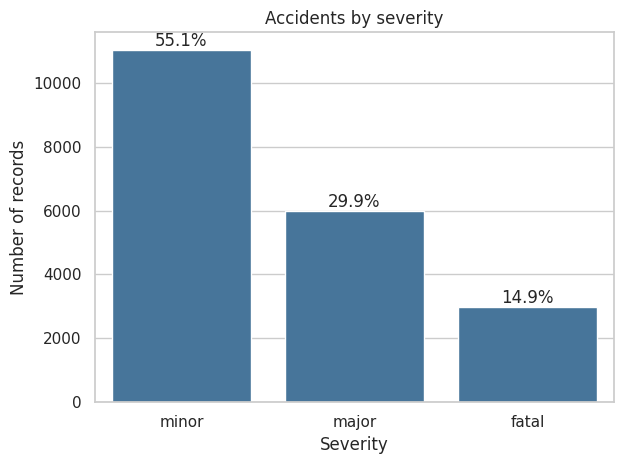

In [6]:
severity_order = ["minor", "major", "fatal"]
severity_summary = (df["accident_severity"].value_counts()
                    .reindex(severity_order, fill_value=0)
                    .rename_axis("severity").to_frame("accident_count"))
severity_summary["percentage"] = severity_summary["accident_count"] / len(df) * 100
severity_summary["percentage"] = severity_summary["percentage"].round(2)
display(severity_summary)

ax = sns.barplot(x=severity_summary.index, y=severity_summary["accident_count"],
                 order=severity_order, color="#3977a8")
ax.set(title="Accidents by severity", xlabel="Severity", ylabel="Number of records")
for i, (_, row) in enumerate(severity_summary.iterrows()):
    ax.text(i, row["accident_count"], f"{row['percentage']:.1f}%", ha="center", va="bottom")
plt.tight_layout(); plt.show()

## PS 2 — Relationship Between Weather and Accident Severity

Use a Pearson chi-square test of independence on weather × severity. Display both raw counts and row percentages (severity distribution within each weather category). Cramér’s V summarizes association strength. This test does not imply weather caused an accident or that weather-specific risk differs; traffic exposure and confounders are unavailable.

Observed counts:


accident_severity,fatal,major,minor
weather,,,
clear,992,2017,3681
fog,995,1975,3663
rain,1000,1996,3681


Row percentages (within weather):


accident_severity,fatal,major,minor
weather,,,
clear,14.8,30.1,55.0
fog,15.0,29.8,55.2
rain,15.0,29.9,55.1


Weather × accident severity: χ²(4) = 0.266, p = 0.9919, Cramér’s V = 0.003, n = 20,000
Minimum expected count = 990.64; cells with expected count < 5 = 0
Decision at α = 0.05: no statistically significant association detected


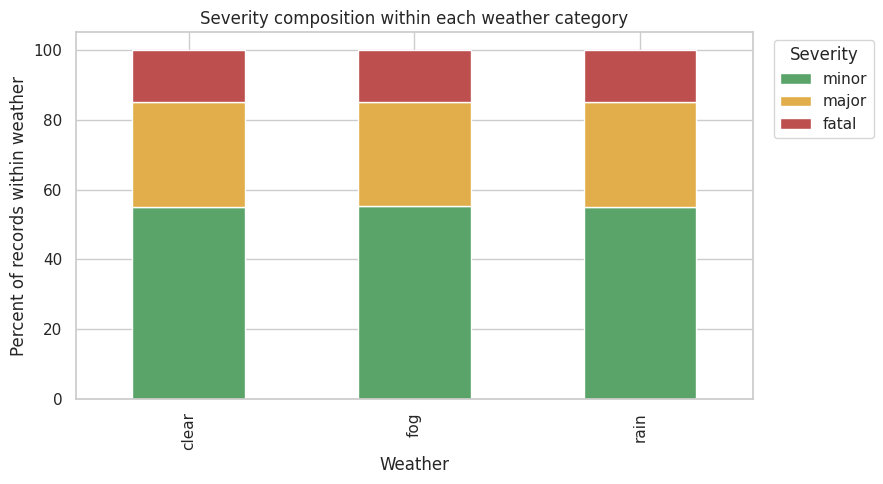

In [7]:
weather_severity, weather_test = categorical_association(df, "weather", "accident_severity", "Weather × accident severity")
print("Observed counts:"); display(weather_severity)
print("Row percentages (within weather):"); display((weather_severity.div(weather_severity.sum(axis=1), axis=0) * 100).round(1))
show_test(weather_test)

weather_pct = weather_severity.div(weather_severity.sum(axis=1), axis=0) * 100
weather_pct = weather_pct.reindex(columns=severity_order, fill_value=0)
weather_pct.plot(kind="bar", stacked=True, figsize=(9, 5), color=["#5aa469", "#e2ad4b", "#bd4f4f"])
plt.title("Severity composition within each weather category")
plt.xlabel("Weather"); plt.ylabel("Percent of records within weather"); plt.legend(title="Severity", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

## PS 3 — Temporal Patterns in Road Accidents

Plot hourly counts, mean daily counts by calendar weekday, and compare per-calendar-day accident counts on weekend versus weekday dates using the Mann–Whitney U test. Date-level aggregation accounts for different numbers of weekday/weekend dates in the observation window. A Kruskal–Wallis test compares daily counts across the seven weekdays. These are count-pattern comparisons only; no traffic volume or population-at-risk denominator is available.

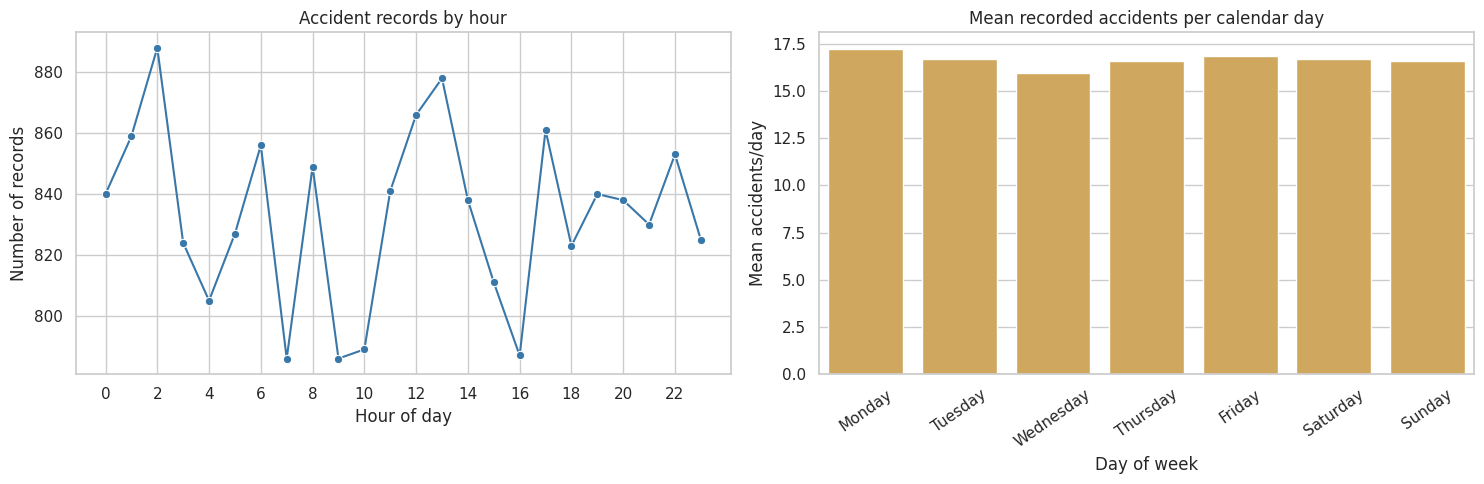

Hourly record counts:


,accident_count
hour,
0,840
1,859
2,888
3,824
4,805
5,827
6,856
7,786
8,849


Daily counts by weekday (dates are the analysis units):


,mean,median,std,count
weekday,,,,
Monday,17.244,17.0,4.471,172
Tuesday,16.692,16.0,4.130,172
Wednesday,15.942,16.0,4.307,171
Thursday,16.579,16.0,4.258,171
Friday,16.836,17.0,3.886,171
Saturday,16.669,16.0,4.073,172
Sunday,16.605,16.0,3.939,172


Weekend vs weekday daily counts: Mann–Whitney U = 145168.5, p = 0.68; median weekend=16.00 (344 dates), weekday=16.00 (857 dates).
Daily counts across weekdays: Kruskal–Wallis H(6) = 8.460, p = 0.2063.


In [8]:
# Hourly record counts (hours with no accidents are retained).
hour_counts = df["hour"].value_counts().reindex(range(24), fill_value=0).sort_index()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.lineplot(x=hour_counts.index, y=hour_counts.values, marker="o", ax=axes[0], color="#3977a8")
axes[0].set(title="Accident records by hour", xlabel="Hour of day", ylabel="Number of records", xticks=range(0, 24, 2))

# Reindex every calendar date to include dates with zero observed records.
daily = df.dropna(subset=["date"]).groupby("date").size()
calendar = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
daily = daily.reindex(calendar, fill_value=0).rename("accident_count").to_frame()
daily["weekday"] = daily.index.day_name()
daily["weekend"] = (daily.index.dayofweek >= 5)
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_daily = daily.groupby("weekday")["accident_count"].agg(["mean", "median", "std", "count"]).reindex(weekday_order)
sns.barplot(x=weekday_daily.index, y=weekday_daily["mean"], ax=axes[1], color="#e2ad4b")
axes[1].set(title="Mean recorded accidents per calendar day", xlabel="Day of week", ylabel="Mean accidents/day")
axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()
print("Hourly record counts:"); display(hour_counts.rename("accident_count").to_frame())
print("Daily counts by weekday (dates are the analysis units):"); display(weekday_daily.round(3))

# Nonparametric comparisons of daily counts.
weekend_daily = daily.loc[daily["weekend"], "accident_count"]
weekday_daily_counts = daily.loc[~daily["weekend"], "accident_count"]
u_stat, p_weekend = stats.mannwhitneyu(weekend_daily, weekday_daily_counts, alternative="two-sided")
print(f"Weekend vs weekday daily counts: Mann–Whitney U = {u_stat:.1f}, p = {p_weekend:.4g}; "
      f"median weekend={weekend_daily.median():.2f} ({len(weekend_daily)} dates), "
      f"weekday={weekday_daily_counts.median():.2f} ({len(weekday_daily_counts)} dates).")
weekday_groups = [daily.loc[daily["weekday"] == day, "accident_count"].to_numpy() for day in weekday_order]
kw_stat, p_weekday = stats.kruskal(*weekday_groups)
print(f"Daily counts across weekdays: Kruskal–Wallis H(6) = {kw_stat:.3f}, p = {p_weekday:.4g}.")

## PS 4 — Road Type, Traffic Density, and Accident Causes

Cross-tabulate accident-record counts for road type × traffic density, road type × cause, and traffic density × cause. Use chi-square independence tests and Cramér’s V to quantify categorical associations. Heatmaps and stacked counts aid interpretation. These compare the composition of recorded accidents, not road-specific accident rates.


Road type × traffic density — observed counts


traffic_density,high,low,medium
road_type,,,
highway,2277,2372,1967
rural,2385,2282,1972
urban,2372,2413,1960


Road type × traffic density: χ²(4) = 5.410, p = 0.2478, Cramér’s V = 0.012, n = 20,000
Minimum expected count = 1951.39; cells with expected count < 5 = 0
Decision at α = 0.05: no statistically significant association detected

Road type × cause — observed counts


cause,distraction,drunk driving,overspeeding,poor road,weather
road_type,,,,,
highway,1390,1283,1302,1261,1380
rural,1331,1347,1356,1301,1304
urban,1305,1348,1367,1412,1313


Road type × cause: χ²(8) = 17.124, p = 0.02885, Cramér’s V = 0.021, n = 20,000
Minimum expected count = 1314.60; cells with expected count < 5 = 0
Decision at α = 0.05: evidence of association

Traffic density × cause — observed counts


cause,distraction,drunk driving,overspeeding,poor road,weather
traffic_density,,,,,
high,1388,1371,1468,1394,1413
low,1431,1413,1423,1394,1406
medium,1207,1194,1134,1186,1178


Traffic density × cause: χ²(8) = 6.526, p = 0.5886, Cramér’s V = 0.013, n = 20,000
Minimum expected count = 1172.13; cells with expected count < 5 = 0
Decision at α = 0.05: no statistically significant association detected


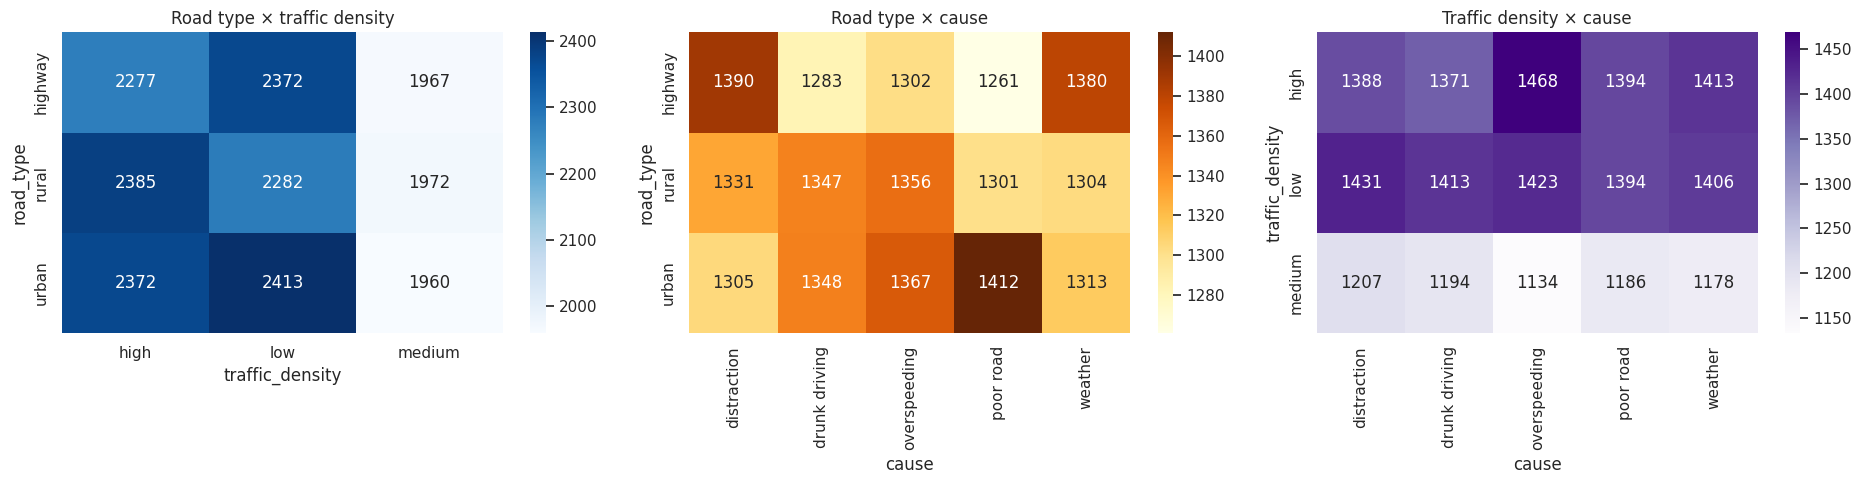

cause,distraction %,drunk driving %,overspeeding %,poor road %,weather %
road_type,,,,,
highway,21.0,19.4,19.7,19.1,20.9
rural,20.0,20.3,20.4,19.6,19.6
urban,19.3,20.0,20.3,20.9,19.5


cause,distraction %,drunk driving %,overspeeding %,poor road %,weather %
traffic_density,,,,,
high,19.7,19.5,20.9,19.8,20.1
low,20.2,20.0,20.1,19.7,19.9
medium,20.5,20.2,19.2,20.1,20.0


In [9]:
road_density, road_density_test = categorical_association(df, "road_type", "traffic_density", "Road type × traffic density")
road_cause, road_cause_test = categorical_association(df, "road_type", "cause", "Road type × cause")
density_cause, density_cause_test = categorical_association(df, "traffic_density", "cause", "Traffic density × cause")
for table, result in [(road_density, road_density_test), (road_cause, road_cause_test), (density_cause, density_cause_test)]:
    print(f"\n{result['comparison']} — observed counts")
    display(table)
    show_test(result)

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
sns.heatmap(road_density, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Road type × traffic density")
sns.heatmap(road_cause, annot=True, fmt="d", cmap="YlOrBr", ax=axes[1])
axes[1].set_title("Road type × cause")
sns.heatmap(density_cause, annot=True, fmt="d", cmap="Purples", ax=axes[2])
axes[2].set_title("Traffic density × cause")
plt.tight_layout(); plt.show()

# Within-group cause composition (row percentages) helps compare category mixes.
display((road_cause.div(road_cause.sum(axis=1), axis=0) * 100).round(1).add_suffix(" %"))
display((density_cause.div(density_cause.sum(axis=1), axis=0) * 100).round(1).add_suffix(" %"))

## PS 5 — Factors Associated with Accident Casualties

Compare casualty distributions across severity groups and vehicle counts using Kruskal–Wallis tests; estimate monotonic association between vehicles involved and casualties with Spearman’s rho. Report medians and means, as casualty counts may be skewed. These are associations; severity may itself be defined partly by harm, so severity/casualty association may be structurally expected. No causal effect is estimated.

Casualties by severity:


,count,mean,median,std
accident_severity,,,,
minor,11025,1.507,1.0,1.390
major,5988,1.495,1.0,1.376
fatal,2987,3.002,3.0,1.416


Casualties by vehicles involved:


,count,mean,median,std
vehicles_involved,,,,
1,4030,0.573,1.0,0.495
2,4030,1.161,1.0,0.825
3,4007,1.714,2.0,1.172
4,3936,2.313,2.0,1.487
5,3997,2.895,3.0,1.800


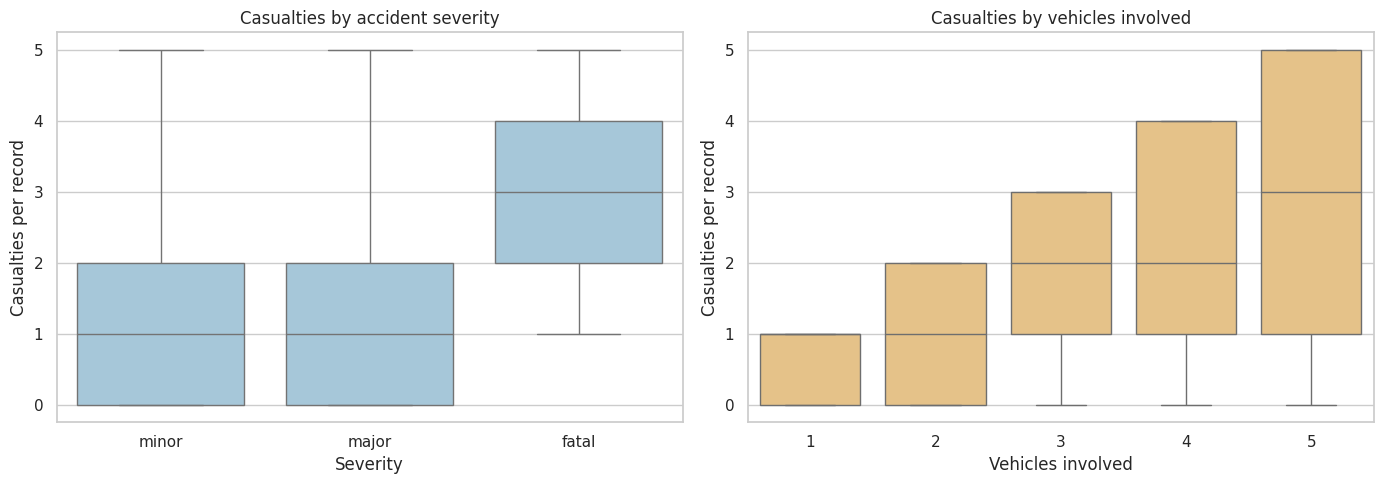

Casualties across severity groups: Kruskal–Wallis H(2) = 2341.613, p = 0.
Casualties across vehicle-count groups: Kruskal–Wallis H = 5352.870, p = 0.
Vehicles involved vs casualties: Spearman ρ = 0.513, p = 0.


In [10]:
severity_casualties = df.groupby("accident_severity", observed=False)["casualties"].agg(["count", "mean", "median", "std"]).reindex(severity_order)
vehicles_casualties = df.groupby("vehicles_involved", observed=False)["casualties"].agg(["count", "mean", "median", "std"])
print("Casualties by severity:"); display(severity_casualties.round(3))
print("Casualties by vehicles involved:"); display(vehicles_casualties.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=df, x="accident_severity", y="casualties", order=severity_order, ax=axes[0], color="#9ecae1", showfliers=False)
axes[0].set(title="Casualties by accident severity", xlabel="Severity", ylabel="Casualties per record")
sns.boxplot(data=df, x="vehicles_involved", y="casualties", ax=axes[1], color="#f4c67a", showfliers=False)
axes[1].set(title="Casualties by vehicles involved", xlabel="Vehicles involved", ylabel="Casualties per record")
plt.tight_layout(); plt.show()

severity_groups = [df.loc[df["accident_severity"] == s, "casualties"].dropna().to_numpy() for s in severity_order]
h_sev, p_sev = stats.kruskal(*severity_groups)
vehicle_groups = [g["casualties"].dropna().to_numpy() for _, g in df.groupby("vehicles_involved", observed=True)]
h_vehicle, p_vehicle = stats.kruskal(*vehicle_groups)
rho, p_rho = stats.spearmanr(df["vehicles_involved"], df["casualties"], nan_policy="omit")
print(f"Casualties across severity groups: Kruskal–Wallis H(2) = {h_sev:.3f}, p = {p_sev:.4g}.")
print(f"Casualties across vehicle-count groups: Kruskal–Wallis H = {h_vehicle:.3f}, p = {p_vehicle:.4g}.")
print(f"Vehicles involved vs casualties: Spearman ρ = {rho:.3f}, p = {p_rho:.4g}.")

## Summary and reporting checklist

Use the printed summaries and tests above to complete a concise findings section after running the notebook. Include, for each test, the test statistic, degrees of freedom (when applicable), p-value, sample size, and an effect size where available. Report non-significant results as “no statistically significant association detected,” not as proof of no relationship.

### Important limitations
- **No exposure denominator:** accident counts do not reveal risk per vehicle, trip, kilometre, or person.
- **Observational data:** association does not establish causation; confounding may remain.
- **Temporal coverage:** date counts describe the observed interval only; traffic patterns and reporting may change by season/year.
- **Multiple comparisons:** several exploratory tests are run; interpret p-values cautiously and consider a multiplicity adjustment for confirmatory work.
- **Data construction/measurement:** verify category definitions and how severity, casualties, and traffic density were recorded before policy use. Missing festival labels are not interpreted.
- **Generalization:** findings apply to the supplied dataset and are not automatically representative of all Indian roads.